# 트랜스포머(GPT) 실습

## 실습 목표
1. GPT-2 아키텍처를 **MoE, RoPE, GQA 같은 최신 확장 없이** 가장 컴팩트한 원형(original)
   형태로 직접 구현 (Karpathy의 **nanoGPT**를 사용)
2. HuggingFace에 공개된 **GPT-2 사전학습 가중치**를 우리가 만든 모델에 그대로 가져와
   원본 HuggingFace 모델과 출력이 동일한지 검증
3. Self-attention의 attention weight를 직접 뽑아 **히트맵으로 시각화**
4. 아주 작은 GPT를 처음부터 학습

## 참고
- 원본 저장소: [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT)
- 이 노트북은 nanoGPT의 `model.py`를 교육용으로 재구성한 것


## 0. 환경 준비


In [1]:
# !pip install torch transformers tiktoken matplotlib -q

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. 모델 구현

### 1-1. 설정값 (Config)


In [2]:
@dataclass
class GPTConfig:
    block_size: int = 1024      # 최대 시퀀스 길이 (context window)
    vocab_size: int = 50257     # GPT-2 BPE 어휘 크기
    n_layer: int = 12           # transformer block 수
    n_head: int = 12            # multi-head self-attention의 head 수
    n_embd: int = 768           # embedding 차원
    dropout: float = 0.0
    bias: bool = True           # GPT-2와 동일하게 Linear/LayerNorm에 bias 사용
    attmap: bool = False        # 시각화를 위해 attention map을 저장할지 여부


### 1-2. Causal Self-Attention

$$
\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V
$$

- $M$은 causal mask로, $i$번째 토큰이 $j>i$번째(미래) 토큰을 보지 못하도록 $-\infty$를 더해 softmax값이 0이되도록 함
- Query, Key, Value는 하나의 `Linear`로 한 번에 계산한 뒤 세 조각으로 split (GPT-2 구현 방식).
- `self.last_attn`에 attention weight를 저장해두어, 이후 시각화에 사용


In [ ]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.config = config
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head  # 768 / 12 = 64

        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)

        mask = torch.tril(torch.ones(config.block_size, config.block_size))
        self.register_buffer("causal_mask", 
                             mask.view(1, 1, config.block_size, config.block_size))

        self.last_attn = None  # 시각화용: 마지막 forward의 attention weight 
                               # (B, n_head, T, T)

    def forward(self, x, attention_mask=None):
        B, T, C = x.shape

        # ---- fill here ----


### 1-3. Feed-Forward(MLP), Transformer Block, 전체 GPT

- MLP: $C \to 4C \to C$ 로 확장했다 줄이며, 활성함수는 GELU를 사용합니다 (GPT-2와 동일).
- Block: **Pre-LayerNorm** 구조로 $x = x + \text{Attn}(\text{LN}(x))$, $x = x + \text{MLP}(\text{LN}(x))$.


In [ ]:
class MLP(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias)
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        # ---- fill here ----


class Block(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd, elementwise_affine=config.bias)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd, elementwise_affine=config.bias)
        self.mlp = MLP(config)

    def forward(self, x, attention_mask=None):
        # ---- fill here ----


In [ ]:
class GPT(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),   # token embedding
            wpe=nn.Embedding(config.block_size, config.n_embd),   # position embedding
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd, elementwise_affine=config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight tying: 입력 임베딩과 출력 projection이 같은 파라미터를 공유
        self.transformer.wte.weight = self.lm_head.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None, attention_mask=None):
        # ---- fill here ----

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        # generate()는 padding 없이 한 문장씩 생성하는 것을 가정하므로 attention_mask는 항상 None
        # ---- fill here ----

    def get_attn_maps(self):
        '''마지막 forward 호출에서 각 레이어의 attention weight 리스트를 반환한다.'''
        return [block.attn.last_attn for block in self.transformer.h]

    @classmethod
    def from_pretrained(cls, model_type="gpt2"):
        '''HuggingFace의 사전학습 GPT-2 가중치를 우리 모델로 복사해 불러온다.'''
        from transformers import GPT2LMHeadModel

        config_args = {
            "gpt2":        dict(n_layer=12, n_head=12, n_embd=768),   # 124M
            "gpt2-medium": dict(n_layer=24, n_head=16, n_embd=1024),  # 350M
            "gpt2-large":  dict(n_layer=36, n_head=20, n_embd=1280),  # 774M
            "gpt2-xl":     dict(n_layer=48, n_head=25, n_embd=1600),  # 1.5B
        }[model_type]
        config_args["vocab_size"] = 50257
        config_args["block_size"] = 1024
        config = GPTConfig(**config_args)
        model = cls(config)
        sd = model.state_dict()
        sd_keys = [k for k in sd.keys() if not k.endswith(".causal_mask")]

        hf_model = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = hf_model.state_dict()
        sd_keys_hf = [k for k in sd_hf.keys()
                      if not k.endswith(".attn.bias") and not k.endswith(".attn.masked_bias")]

        # HuggingFace GPT2는 Conv1D를 사용해 Linear와 weight 방향이 반대(transpose 필요)
        transposed = ["attn.c_attn.weight", "attn.c_proj.weight", "mlp.c_fc.weight", "mlp.c_proj.weight"]

        assert len(sd_keys) == len(sd_keys_hf), f"key 개수 불일치: {len(sd_keys)} vs {len(sd_keys_hf)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model


## 2. Smoke Test

일단 GPT-2를 로드하거나 학습하기 전에 작은 모델을 생성하고 랜덤 입력을 넣어 보아 정상 동작하는지 확인


In [23]:
cfg = GPTConfig(block_size=64, vocab_size=100, n_layer=2, n_head=2, n_embd=32)
tiny_model = GPT(cfg)

x = torch.randint(0, 100, (4, 16))
y = torch.randint(0, 100, (4, 16))
logits, loss = tiny_model(x, y)
print("logits shape:", logits.shape, " loss:", loss.item())

loss.backward()
print("backward 통과. 총 파라미터 수:", sum(p.numel() for p in tiny_model.parameters()))

out = tiny_model.generate(torch.zeros((1, 1), dtype=torch.long), max_new_tokens=10, top_k=5)
print("generate 결과:", out.shape)


logits shape: torch.Size([4, 16, 100])  loss: 4.604998588562012
backward 통과. 총 파라미터 수: 30720
generate 결과: torch.Size([1, 11])


## 3. GPT-2 사전학습 가중치 불러오기

가능한 모델:
* "gpt2": n_layer=12, n_head=12, n_embd=768, 124M
* "gpt2-medium": n_layer=24, n_head=16, n_embd=1024, 350M
* "gpt2-large": n_layer=36, n_head=20, n_embd=1280, 774M
* "gpt2-xl": n_layer=48, n_head=25, n_embd=1600, 1.5B

In [24]:
model = GPT.from_pretrained("gpt2")
model.eval()
model.to(device)
print("GPT-2 로드 완료. 총 파라미터 수:", sum(p.numel() for p in model.parameters()))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 로드 완료. 총 파라미터 수: 124439808


### 토크나이저 로딩

GPT2Tokenizer 사용

In [25]:
from transformers import GPT2Tokenizer

tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

## 4. 텍스트 생성 데모

GPT-2 토크나이저(BPE)로 프롬프트를 인코딩하고, 우리 모델로 이어서 생성

In [26]:
def generate_text(prompt, max_new_tokens=40, temperature=0.8, top_k=40):
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model.generate(
            input_ids, 
            max_new_tokens=max_new_tokens, 
            temperature=temperature, 
            top_k=top_k)
    return tokenizer.decode(out[0].tolist())

print(generate_text("In this course of natural language processing, we will learn about"))


In this course of natural language processing, we will learn about how the human brain learns and interprets various languages, and will build on this to better understand human language processing in the context of other systems. We will discuss the role of brain activity for human language


## 5. Attention 시각화

* 프롬프트 하나를 forward pass 시킨 뒤, `get_attn_maps()`로 각 레이어의 attention weight를
꺼내 히트맵으로 plotting.
* 행이 "질의(현재 토큰)", 열이 "키(주목하는 대상 토큰)"이며,
causal mask 때문에 오른쪽 위 삼각형은 항상 0


In [27]:
model.config.attmap = True

prompt = "The cat sat on the mat because it was tired"
input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)
tokens = [tokenizer.decode([t]) for t in input_ids[0].tolist()]

with torch.no_grad():
    _ = model(input_ids)
attn_maps = model.get_attn_maps()  # 길이 = 레이어 수, 각 원소 shape = (1, n_head, T, T)

print(f"레이어 수: {len(attn_maps)}, 헤드 수: {attn_maps[0].shape[1]}, 토큰 수: {len(tokens)}")
print("토큰:", tokens)


레이어 수: 12, 헤드 수: 12, 토큰 수: 10
토큰: ['The', ' cat', ' sat', ' on', ' the', ' mat', ' because', ' it', ' was', ' tired']


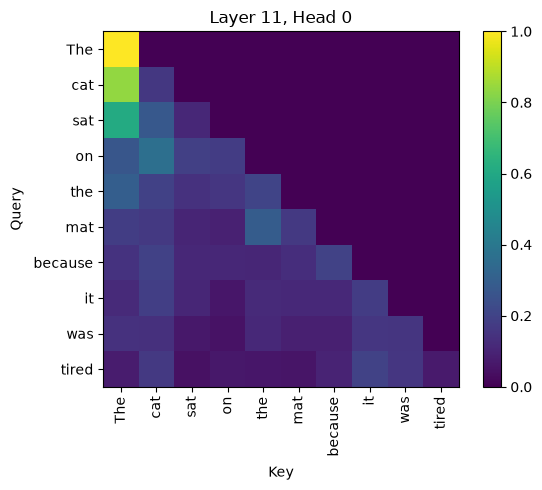

In [28]:
def plot_attention(layer_idx, head_idx):
    att = attn_maps[layer_idx][0, head_idx].cpu().numpy()  # (T, T)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(att, cmap="viridis")
    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticklabels(tokens)
    ax.set_xlabel("Key")
    ax.set_ylabel("Query")
    ax.set_title(f"Layer {layer_idx}, Head {head_idx}")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

# 마지막 레이어의 0번째 헤드 (보통 문법적/지역적 패턴이 잘 보입니다)
plot_attention(layer_idx=len(attn_maps) - 1, head_idx=0)


**관찰 포인트**
- 초반 레이어(L0)는 주로 **바로 이전 토큰이나 첫 토큰**처럼 위치적으로 가까운 패턴에 주목하는 경우가 많음
- 마지막 레이어로 갈수록 **의미적으로 관련된 먼 토큰**(예: "it"이 가리키는 "cat")에 주목 가능
- 헤드마다 서로 다른 패턴을 학습한다는 것이 멀티헤드 어텐션의 요점


# 6. 영한 기계번역 학습
- LSTM기반 `mnt` 실습에서 사용한 한영 데이터셋 사용 (kor_gpt.txt)
- 소형 모델 기반 처음부터 학습

In [13]:
import json
import urllib.request
import os

# Download data files if not exist
data_urls = {
    'kor_gpt.txt': 'https://raw.githubusercontent.com/hyerica-bdml/class-2026-nlp/refs/heads/main/data/kor_gpt.txt'
}

for filename, url in data_urls.items():
    if not os.path.exists(filename):
        print(f'Downloading {filename}...')
        urllib.request.urlretrieve(url, filename)
        print(f'{filename} downloaded.')
    else:
        print(f'{filename} already exists.')

with open('kor_gpt.txt', 'r', encoding='utf-8') as f:
    lines = f.readlines()

kor_gpt.txt already exists.


In [14]:
en_lines, ko_lines = zip(*[line.split("<trans>") for line in lines])

영어 tokenizer와 한글 tokenizer로딩

In [15]:
import nltk
nltk.download('punkt_tab')
print(nltk.word_tokenize(en_lines[-1].lower()))

['doubtless', 'there', 'exists', 'in', 'this', 'world', 'precisely', 'the', 'right', 'woman', 'for', 'any', 'given', 'man', 'to', 'marry', 'and', 'vice', 'versa', ';', 'but', 'when', 'you', 'consider', 'that', 'a', 'human', 'being', 'has', 'the', 'opportunity', 'of', 'being', 'acquainted', 'with', 'only', 'a', 'few', 'hundred', 'people', ',', 'and', 'out', 'of', 'the', 'few', 'hundred', 'that', 'there', 'are', 'but', 'a', 'dozen', 'or', 'less', 'whom', 'he', 'knows', 'intimately', ',', 'and', 'out', 'of', 'the', 'dozen', ',', 'one', 'or', 'two', 'friends', 'at', 'most', ',', 'it', 'will', 'easily', 'be', 'seen', ',', 'when', 'we', 'remember', 'the', 'number', 'of', 'millions', 'who', 'inhabit', 'this', 'world', ',', 'that', 'probably', ',', 'since', 'the', 'earth', 'was', 'created', ',', 'the', 'right', 'man', 'has', 'never', 'yet', 'met', 'the', 'right', 'woman', '.']


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Younghoon\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [17]:
from kiwipiepy import Kiwi
kiwi = Kiwi()
print([ w.form for w in kiwi.tokenize(ko_lines[-1]) ])

['의심', '의', '여지', '없이', '세상', '에', '는', '어떤', '남자', '이', '든', '정확히', '딱', '알맞', '는', '여자', '와', '결혼', '하', '거나', '그', '반대', '의', '상황', '이', '존재', '하', '지', '.', '그런데', '인간', '이', '수백', '명', '의', '사람', '만', '알', '고', '지내', '는', '사이', '가', '되', 'ᆯ', '기회', '를', '갖', '는다고', '생각', '하', '어', '보', '면', ',', '또', '그', '수백', '명', '중', '열', '여', '명', '쯤', '이하', '만', '잘', '알', 'ᆯ', '수', '있', '고', ',', '그리고', '나', '어서', '그', '열', '여', '명', '중', '에', '한두', '명', '만', '친구', '가', '되', 'ᆯ', '수', '있', '다면', ',', '그리고', '또', '만일', '우리', '가', '이', '세상', '에', '살', '고', '있', '는', '수백만', '명', '의', '사람', '들', '만', '기억', '하', '고', '있', '다면', ',', '딱', '맞', '는', '남자', '는', '지구', '가', '생겨나', 'ᆫ', '이래', '로', '딱', '맞', '는', '여자', '를', '단', '한', '번', '도', '만나', 'ᆫ', '적', '이', '없', '을', '수', '도', '있', '을', '거', '이', '라는', '사실', '을', '쉽', '게', '눈치', '채', 'ᆯ', '수', '있', '을', '거', '이', '야', '.']


In [18]:
x_tokens = [ nltk.word_tokenize(x.lower()) for x in en_lines ]
y_tokens = [ [ w.form for w in kiwi.tokenize(x) ] for x in ko_lines ]

In [ ]:
import numpy as np

# GPT는 encoder와 decoder 구분이 없으므로 한글과 영어 토큰을 합쳐서 인코딩
def text_encoding(x_lines, y_lines):
    assert len(x_lines) == len(y_lines)
    vocab, index = {}, 6  # start indexing from 6
    vocab['<pad>'] = 0  # add a padding token
    vocab['<xbos>'] = 1  # begin of x sentence
    vocab['<xeos>'] = 2  # end of x sentence
    vocab['<ybos>'] = 3  # begin of y sentence
    vocab['<yeos>'] = 4  # end of y sentence
    vocab['<trans>'] = 5  # translation

    # vocab 생성
    maxlen = -1
    for sentence1, sentence2 in zip(x_lines, y_lines):
        for token in sentence1 + sentence2:
            if token not in vocab:
                vocab[token] = index
                index += 1
        
        if maxlen < len(sentence1 + sentence2):
            maxlen = len(sentence1 + sentence2)

    # 인코딩하여 x_arr, y_arr 생성 (최대 길이 = maxlen + 5)
    arr = np.zeros((len(x_lines), maxlen+5), dtype='int32')

    for i, (sentence1, sentence2) in enumerate(zip(x_lines, y_lines)):
        assert len(sentence1) > 0
        # x sentence 인코딩
        idx = 0
        arr[i, idx] = vocab['<xbos>']
        idx += 1
        for token in sentence1:
            arr[i, idx] = vocab[token]
            idx += 1
        arr[i, idx] = vocab['<xeos>']
        idx += 1

        arr[i, idx] = vocab['<trans>']
        idx += 1

        if len(sentence2) > 0:
            arr[i, idx] = vocab['<ybos>']
            idx += 1
            # y sentence 인코딩
            for token in sentence2:
                arr[i, idx] = vocab[token]
                idx += 1
            arr[i, idx] = vocab['<yeos>']

    return arr, vocab

In [ ]:
train, vocab = text_encoding(x_tokens, y_tokens)
np.random.shuffle(train)
x_train, x_val = train[:int(len(train)*0.9)], train[int(len(train)*0.9):]

In [33]:
inverse_vocab = {index: token for token, index in vocab.items()}

In [23]:
def text_decoding(line, invvocab):
    return [ invvocab[x] for x in line]

In [34]:
print(text_decoding(x_train[-1], inverse_vocab))

['<xbos>', 'tom', 'divided', 'the', 'pie', 'into', 'three', 'equal', 'parts', '.', '<xeos>', '<trans>', '<ybos>', '톰', '이', '파이', '를', '삼', '등분', '으로', '나누', '었', '어', '.', '<yeos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>'

In [25]:
x_train.shape,len(vocab)

((3356, 280), 5061)

In [27]:
BATCH_SIZE = 16
vocab_size = len(vocab)

In [44]:
BATCH_SIZE = 64

In [45]:
import torch
from torch.utils.data import Dataset, DataLoader

def crop_padding_collate_fn(batch, pad_token_id=0):
    """
    batch: 이미 고정 길이로 패딩된 텐서들의 리스트, 예: 각각 (256,)
    이 배치 안에서 실제로 필요한 길이까지만 뒤쪽을 잘라냄
    """
    input_ids = torch.stack(batch)  # (batch_size, max_len)

    batch_max_len = (input_ids != pad_token_id).sum(dim=1).max().item()
    cropped_input_ids = input_ids[:, :batch_max_len]

    attention_mask = (cropped_input_ids != pad_token_id).long()

    return {
        "input_ids": cropped_input_ids[:, :-1],
        "target_ids": cropped_input_ids[:, 1:].contiguous(),
        "attention_mask": attention_mask[:, :-1],
    }

class TranslationDataset(Dataset):
    def __init__(self, x_data):
        self.x_data = torch.LongTensor(x_data)
    
    def __len__(self):
        return len(self.x_data)
    
    def __getitem__(self, idx):
        return self.x_data[idx]

dataset = TranslationDataset(x_train)
dataloader = DataLoader(
    dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    collate_fn=crop_padding_collate_fn)


val_dataset = TranslationDataset(x_val)
val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    collate_fn=crop_padding_collate_fn)


In [40]:
for example_input_batch in dataloader:
    print(example_input_batch.get('input_ids')[:2])
    print()
    break

tensor([[   1,  115, 2092,  478, 1141, 3937,  726,  428,    7,    2,    5,    3,
          116,   85,   58,   27,  269,   77, 1174, 1998,   85,  555,  117,  989,
         2093,    7,    4],
        [   1,  115, 1294,   97, 2663, 3329,    7,    2,    5,    3,  116,   85,
           82,   98, 2664, 2692,  117, 1297,   37,   14,    7,    4,    0,    0,
            0,    0,    0]])



In [41]:
block_size = x_train.shape[1]
batch_size = 16

torch.manual_seed(0)
mini_cfg = GPTConfig(block_size=block_size, vocab_size=vocab_size, n_layer=6, n_head=8, n_embd=256, dropout=0.1)
mini_model = GPT(mini_cfg)
print("파라미터 수:", sum(p.numel() for p in mini_model.parameters()))


파라미터 수: 6106368


In [42]:
mini_cfg

GPTConfig(block_size=280, vocab_size=5061, n_layer=6, n_head=8, n_embd=256, dropout=0.1, bias=True, attmap=False)

In [46]:
optimizer = torch.optim.AdamW(mini_model.parameters(), lr=3e-3)

train_losses, val_losses, steps_log = [], [], []

for step in range(300):
    loss_sum = 0
    for bat in dataloader:
        logits, loss = mini_model(
            bat['input_ids'], 
            bat['target_ids'], 
            attention_mask=bat['attention_mask'])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_sum += loss.item()

    if step % 20 == 0 or step == 299:
        mini_model.eval()
        vloss_sum = 0
        with torch.no_grad():
            for bat in val_dataloader:
                _, vloss = mini_model(bat['input_ids'], bat['target_ids'], attention_mask=bat['attention_mask'])
                vloss_sum += vloss.item()
        mini_model.train()
        train_losses.append(loss_sum / len(dataloader))
        val_losses.append(vloss_sum / len(val_dataloader))
        steps_log.append(step)
        print(f"step {step:4d}  train loss {loss.item():.3f}  val loss {vloss.item():.3f}")


step    0  train loss 2.568  val loss 0.955
step   20  train loss 1.811  val loss 1.097
step   40  train loss 1.780  val loss 1.170
step   60  train loss 1.329  val loss 1.227
step   80  train loss 1.328  val loss 1.289
step  100  train loss 1.359  val loss 1.332
step  120  train loss 1.204  val loss 1.309
step  140  train loss 1.153  val loss 1.332
step  160  train loss 1.136  val loss 1.296
step  180  train loss 1.237  val loss 1.332
step  200  train loss 1.048  val loss 1.379
step  220  train loss 1.172  val loss 1.330
step  240  train loss 1.102  val loss 1.401
step  260  train loss 0.989  val loss 1.375
step  280  train loss 0.898  val loss 1.419
step  299  train loss 0.841  val loss 1.448


In [75]:
test_line = [ vocab['<xbos>'] ] + [ vocab.get(token, vocab.get('<UNK>')) for token in nltk.word_tokenize("I think Tom is a good poet.".lower()) ] + [ vocab['<xeos>'], vocab['<trans>'], vocab['<ybos>'] ]
line = torch.LongTensor(test_line).unsqueeze(0)
print(" ".join(text_decoding(line[0].tolist(), inverse_vocab)))
with torch.no_grad():
    out = mini_model.generate(line, max_new_tokens=40, temperature=0.8, top_k=10)
    print(" ".join(text_decoding(out[0].tolist(), inverse_vocab)))

<xbos> i think tom is a good poet . <xeos> <trans> <ybos>
<xbos> i think tom is a good poet . <xeos> <trans> <ybos> 톰 은 아주 관대 하 ᆫ 것 같 어 . <yeos> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>


In [65]:
test_sentences = [
    "I think Tom is a good poet.",
    "My brother has never been robbed.",
    "I don't want to buy a car right now.",
    "Tom decided to help me with my French.",
    "How many books did you buy this morning?",
    "I'm learning French because I love languages.",
    "Tom's daughter is still afraid of spiders.",
    "My dog and I took a walk in the dark.",
    "Tom hasn't eaten dinner yet, has he?"
]

for test_line in test_sentences:
    tokens = [ vocab['<xbos>'] ] + [ vocab.get(token, vocab.get('<UNK>')) for token in nltk.word_tokenize(test_line.lower()) ] + [ vocab['<xeos>'], vocab['<trans>'], vocab['<ybos>'] ]
    line = torch.LongTensor(tokens).unsqueeze(0)
    #print(" ".join(text_decoding(line[0].tolist(), inverse_vocab)))
    with torch.no_grad():
        out = mini_model.generate(line, max_new_tokens=40, temperature=0.4, top_k=10)
        print(" ".join(text_decoding(out[0].tolist(), inverse_vocab)))


<xbos> i think tom is a good poet . <xeos> <trans> <ybos> 톰 이 ᆫ 톰 이 조용 하 ᆫ 톰 이 사진 같 어 . <yeos> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>
<xbos> my brother has never been robbed . <xeos> <trans> <ybos> 나 의 상사 는 강아지 들 은 실패 하 어 . <yeos> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>
<xbos> i do n't want to buy a car right now . <xeos> <trans> <ybos> 나 ᆫ 톰 이 부럽 었 어 . <yeos> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>
<xbos> tom decided to help me with my french . <xeos> <trans> <ybos> 톰 은 메리 를 차 에서 나 것 을 거절 하 었 어 . <yeos> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pa

## 7. 토론

1. 미니 GPT의 `n_layer`, `n_head`, `n_embd`를 바꿔가며 파라미터 수와 loss 감소 속도가
   어떻게 달라지는지 예측하시오. 파라미터가 늘어난다고 항상 좋은 결과가 나올까?
   (힌트: 텍스트 길이 대비 모델 크기)
2. Attention 히트맵에서 대각선 바로 아래(직전 토큰)에 집중하는 헤드와, 문장 앞부분의
   특정 토큰에 집중하는 헤드를 각각 찾아보시오. 왜 이런 차이가 생길까?
3. `temperature`와 `top_k` 값을 바꿔가며 생성 결과가 어떻게 달라지는지 비교하시오.
   왜 temperature가 낮으면 반복적인 문장이 나오기 쉬울까?
1. `GPT.from_pretrained("gpt2-medium")` 혹은 `gpt2-large`로 더 큰 모델을 불러와 동일한 프롬프트에 대한
   attention 패턴과 생성 품질을 비교해보시오.
3. 위의 코드와 같이 `GPT.generate()`를 이용하여 길이 `N`의 시퀀스를 생성할때 시간복잡도를 계산해보시오. `CausalSelfAttention`를 수정하여 생성속도를 향상시키는 방법이 있을까? (힌트: **KV-cache**라는 간단한 방법으로 `generate()`의 수행 속도를 향상시킬 수 있음. KV캐시라는 이름에서 힌트를 얻어보시오.)

## 참고 자료
- Karpathy, *nanoGPT*: https://github.com/karpathy/nanoGPT
- Vaswani et al., "Attention Is All You Need" (2017)
- Radford et al., "Language Models are Unsupervised Multitask Learners" (GPT-2, 2019)
